[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/calculus-and-optimization/limits-and-continuity/notebook.ipynb)

# Limits and Continuity: hands-on

This notebook goes with the [topic README](README.md). You will watch tables of values close in on a limit, draw a hole, a jump, and an asymptote, compute one-sided limits with SymPy, check the limit laws, see the squeeze theorem and the epsilon-delta tolerance game, write a bisection root finder from scratch, compare growth rates, watch $(1+1/n)^n$ head to $e$, see sigmoid, tanh, and softmax saturate, and learn why a finite-difference derivative has a sweet spot for its step size. All data are invented or computed on the spot. It uses NumPy, SymPy, SciPy, and Matplotlib, and runs in a few seconds on a CPU.

Numerical checks hold only up to rounding error, so we compare floats with `np.isclose` and `np.allclose`, never with `==`.

In [1]:
%matplotlib inline
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import xlogy, logsumexp

plt.rcParams["figure.dpi"] = 49
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
np.set_printoptions(precision=6, suppress=True)
x = sp.symbols("x")            # the SymPy symbol used in the symbolic cells below

## 1. Tables of values

A limit asks where $f(x)$ is **heading** as $x$ gets close to $a$. A table of values from both sides is the simplest way to see it. The function below cannot be evaluated at $x = 1$ (it is $0/0$), but the outputs close in on $2$ from both sides.

In [2]:
def approach(func, a, hs=(0.1, 0.01, 0.001, 1e-4, 1e-5)):
    print(f"{'h':>8} {'f(a-h)':>12} {'f(a+h)':>12}")
    for h in hs:
        print(f"{h:>8g} {func(a - h):>12.6f} {func(a + h):>12.6f}")

f = lambda t: (t**2 - 1) / (t - 1)
try:
    f(1)
except ZeroDivisionError as err:
    print("f(1) fails:", err)
approach(f, 1)

f(1) fails: division by zero
       h       f(a-h)       f(a+h)
     0.1     1.900000     2.100000
    0.01     1.990000     2.010000
   0.001     1.999000     2.001000
  0.0001     1.999900     2.000100
   1e-05     1.999990     2.000010


Two more, to see the pattern: $\sin(x)/x$ at $0$ (a famous limit, $x$ in radians) and $\dfrac{\sqrt{x+4}-2}{x}$ at $0$ (which section 3 solves by rationalizing).

In [3]:
print("sin(x)/x as x -> 0")
approach(lambda t: np.sin(t) / t, 0.0)
print("\n(sqrt(x+4) - 2)/x as x -> 0")
approach(lambda t: (np.sqrt(t + 4) - 2) / t, 0.0)

sin(x)/x as x -> 0
       h       f(a-h)       f(a+h)
     0.1     0.998334     0.998334
    0.01     0.999983     0.999983
   0.001     1.000000     1.000000
  0.0001     1.000000     1.000000
   1e-05     1.000000     1.000000

(sqrt(x+4) - 2)/x as x -> 0
       h       f(a-h)       f(a+h)
     0.1     0.251582     0.248457
    0.01     0.250156     0.249844
   0.001     0.250016     0.249984
  0.0001     0.250002     0.249998
   1e-05     0.250000     0.250000


Now the picture. The open circle marks the missing point, and the dashed lines mark where the outputs are heading.

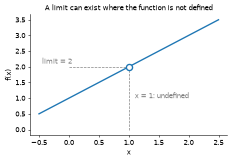

In [4]:
t = np.linspace(-0.5, 2.5, 400)
t = t[~np.isclose(t, 1.0)]
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(t, f(t), lw=2)
ax.plot([1], [2], "o", mfc="white", mec="C0", ms=9, mew=2, zorder=5)
ax.plot([0, 1], [2, 2], "--", color="gray", lw=1)
ax.plot([1, 1], [0, 2], "--", color="gray", lw=1)
ax.text(1.1, 1.0, "x = 1: undefined", color="gray")
ax.text(-0.45, 2.1, "limit = 2", color="gray")
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.set_title("A limit can exist where the function is not defined")
plt.show()

## 2. One-sided limits

The **left-hand limit** looks only at $x < a$, and the **right-hand limit** only at $x > a$. The ordinary limit exists when both exist and agree. For $|x|/x$ they disagree. A SymPy detail worth knowing: `sp.limit(expr, x, a)` looks from the **right** by default, so ask for `"-"`, `"+"`, or `"+-"` (two-sided) explicitly.

In [5]:
g = lambda t: np.abs(t) / t
for h in [0.1, 0.01, 0.001]:
    print(f"h = {h:<6} g(-h) = {g(-h):5.1f}   g(h) = {g(h):5.1f}")

print("left :", sp.limit(sp.Abs(x) / x, x, 0, "-"))
print("right:", sp.limit(sp.Abs(x) / x, x, 0, "+"))
print("default direction is the right side:", sp.limit(sp.Abs(x) / x, x, 0))
try:
    print("two-sided:", sp.limit(sp.Abs(x) / x, x, 0, "+-"))
except ValueError as err:
    print("two-sided: SymPy refuses ->", err)

h = 0.1    g(-h) =  -1.0   g(h) =   1.0
h = 0.01   g(-h) =  -1.0   g(h) =   1.0
h = 0.001  g(-h) =  -1.0   g(h) =   1.0
left : -1
right: 1
default direction is the right side: 1
two-sided: SymPy refuses -> The limit does not exist since left hand limit = -1 and right hand limit = 1


## 3. Limit laws and 0/0 forms

If $\lim f = L$ and $\lim g = M$ exist, then sums, products, and quotients (with $M \ne 0$) behave as expected. Below we approximate each limit by evaluating just next to $a = 2$ (average of both sides) and compare with the law.

In [6]:
def near(func, a, h=1e-7):
    return (func(a - h) + func(a + h)) / 2          # a numerical estimate of the limit

f1 = lambda t: t**2 + 1          # limit L = 5 at a = 2
g1 = lambda t: 2 * t + 3         # limit M = 7 at a = 2
L, M = near(f1, 2), near(g1, 2)
print("L, M =", round(L, 6), round(M, 6))
print("sum     :", np.isclose(near(lambda t: f1(t) + g1(t), 2), L + M))
print("product :", np.isclose(near(lambda t: f1(t) * g1(t), 2), L * M))
print("quotient:", np.isclose(near(lambda t: f1(t) / g1(t), 2), L / M))
print("power   :", np.isclose(near(lambda t: f1(t) ** 3, 2), L ** 3))

L, M = 5.0 7.0
sum     : True
product : True
quotient: True
power   : True


The worked example from the README, $\lim_{x\to2}\frac{3x^2-x+4}{x+1}$, is just "plug in" because the denominator does not vanish. For $0/0$ forms, rewrite first. SymPy does the algebra for us: `factor` and `cancel` for the factor-and-cancel trick, and `limit` for the answer.

In [7]:
print(sp.limit((3*x**2 - x + 4) / (x + 1), x, 2), "  (plug in: 14/3)")

expr = (x**2 - 9) / (x - 3)
print("factor and cancel:", sp.factor(x**2 - 9), "->", sp.cancel(expr), "| limit at 3:", sp.limit(expr, x, 3))

expr = (sp.sqrt(x + 4) - 2) / x
print("rationalize      : top times conjugate =", sp.expand((sp.sqrt(x + 4) - 2) * (sp.sqrt(x + 4) + 2)), "| limit at 0:", sp.limit(expr, x, 0))

h = sp.symbols("h")
expr = (1 / (2 + h) - sp.Rational(1, 2)) / h
print("fraction in fraction:", sp.simplify(expr), "| limit at 0:", sp.limit(expr, h, 0))

14/3   (plug in: 14/3)
factor and cancel: (x - 3)*(x + 3) -> x + 3 | limit at 3: 6
rationalize      : top times conjugate = x | limit at 0: 1/4


fraction in fraction: -1/(2*h + 4) | limit at 0: -1/4


## 4. The squeeze theorem

$x\sin(1/x)$ is not defined at $0$ and wiggles wildly, but it sits between the walls $-|x|$ and $|x|$, which both close in on $0$. Whatever is trapped between them must go to $0$ too.

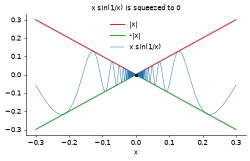

always between the walls: True
x = 0.1    x sin(1/x) = -0.054402   x = -0.1: -0.054402
x = 0.01   x sin(1/x) = -0.005064   x = -0.01: -0.005064
x = 0.001  x sin(1/x) =  0.000827   x = -0.001:  0.000827


In [8]:
tt = np.linspace(-0.3, 0.3, 6001)
tt = tt[~np.isclose(tt, 0.0)]
fig, ax = plt.subplots(figsize=(5.8, 3.2))
ax.plot(tt, np.abs(tt), "C3", lw=1.5, label="|x|")
ax.plot(tt, -np.abs(tt), "C2", lw=1.5, label="-|x|")
ax.plot(tt, tt * np.sin(1 / tt), "C0", lw=0.7, label="x sin(1/x)")
ax.plot([0], [0], "ko", ms=4)
ax.legend(frameon=False, loc="upper center"); ax.set_xlabel("x")
ax.set_title("x sin(1/x) is squeezed to 0")
plt.show()

inside = np.all(np.abs(tt * np.sin(1 / tt)) <= np.abs(tt) + 1e-15)
print("always between the walls:", inside)
for h in [0.1, 0.01, 0.001]:
    print(f"x = {h:<6} x sin(1/x) = {h * np.sin(1 / h): .6f}   x = -{h}: {-h * np.sin(-1 / h): .6f}")

The same kind of argument (using areas in a circle) proves $\lim_{x\to0}\sin(x)/x = 1$. The numbers agree, and the sympy answer in section 1 confirmed it. You will use this limit in the next topic.

In [9]:
for h in [0.5, 0.1, 0.01, 0.001]:
    print(f"x = {h:<6} sin(x)/x = {np.sin(h) / h:.8f}")
print(sp.limit(sp.sin(x) / x, x, 0))

x = 0.5    sin(x)/x = 0.95885108
x = 0.1    sin(x)/x = 0.99833417
x = 0.01   sin(x)/x = 0.99998333
x = 0.001  sin(x)/x = 0.99999983
1


## 5. The tolerance game (epsilon and delta)

You name a tolerance $\varepsilon$ for the output. I must find a $\delta$ so that **every** $x$ within $\delta$ of $a$ (not equal to $a$) has $|f(x) - L| < \varepsilon$. Here is a checker that tests a proposed $\delta$ on a dense grid of points (a numerical check, not a proof), for $f(x) = 2x + 1$ at $a = 3$ with $L = 7$.

In [10]:
def wins(func, a, L, eps, delta, n=20001):
    # does every sampled x with 0 < |x - a| < delta land within eps of L?
    xs = np.linspace(a - delta, a + delta, n)
    xs = xs[~np.isclose(xs, a, rtol=0, atol=1e-12)]
    xs = xs[np.abs(xs - a) < delta]
    return bool(np.all(np.abs(func(xs) - L) < eps))

lin = lambda t: 2 * t + 1
for eps in [1.0, 0.5, 0.1, 0.01]:
    delta = eps / 2                                   # the winning reply from the README
    print(f"eps = {eps:<5} delta = {delta:<6} wins: {wins(lin, 3, 7, eps, delta)}   | delta = 2*eps wins: {wins(lin, 3, 7, eps, 2 * eps)}")

eps = 1.0   delta = 0.5    wins: True   | delta = 2*eps wins: False
eps = 0.5   delta = 0.25   wins: True   | delta = 2*eps wins: False
eps = 0.1   delta = 0.05   wins: True   | delta = 2*eps wins: False
eps = 0.01  delta = 0.005  wins: True   | delta = 2*eps wins: False


A $\delta$ of $\varepsilon/2$ always wins for this line, and a $\delta$ of $2\varepsilon$ never does (it is too generous: points at the edge land outside the band). For a curve such as $x^2$ at $a = 2$, a $\delta$ of $\min(1, \varepsilon/5)$ works.

In [11]:
sq = lambda t: t**2
for eps in [1.0, 0.1, 0.001]:
    delta = min(1, eps / 5)
    print(f"x^2 near 2: eps = {eps:<6} delta = {delta:<8} wins: {wins(sq, 2, 4, eps, delta)}")

x^2 near 2: eps = 1.0    delta = 0.2      wins: True
x^2 near 2: eps = 0.1    delta = 0.02     wins: True
x^2 near 2: eps = 0.001  delta = 0.0002   wins: True


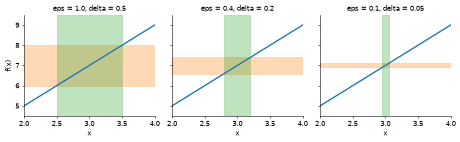

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(9.5, 3), sharey=True)
tt = np.linspace(2.0, 4.0, 100)
for ax, eps in zip(axs, [1.0, 0.4, 0.1]):
    d = eps / 2
    ax.plot(tt, lin(tt), "C0", lw=2)
    ax.axhspan(7 - eps, 7 + eps, color="C1", alpha=0.3)
    ax.axvspan(3 - d, 3 + d, color="C2", alpha=0.3)
    ax.set_title(f"eps = {eps}, delta = {d}"); ax.set_xlabel("x")
    ax.set_xlim(2, 4); ax.set_ylim(4.5, 9.5)
axs[0].set_ylabel("f(x)")
plt.tight_layout(); plt.show()

## 6. Continuity and its types

A function is continuous at $a$ if (1) $f(a)$ is defined, (2) the limit exists, and (3) the limit equals $f(a)$. The helper below runs the three-part test **numerically**: it reads the one-sided values just next to $a$. It is a quick heuristic, not a proof, but it classifies the usual suspects.

In [13]:
def test_continuity(func, a, h=1e-7):
    with np.errstate(all="ignore"):
        value = func(np.float64(a))
        left, right = func(np.float64(a - h)), func(np.float64(a + h))
    defined = bool(np.isfinite(value))
    big = max(abs(left), abs(right)) > 1e5
    limit_exists = (not big) and bool(np.isclose(left, right, atol=1e-5))
    continuous = defined and limit_exists and bool(np.isclose(value, left, atol=1e-5))
    if continuous:
        kind = "continuous"
    elif big:
        kind = "infinite discontinuity"
    elif not limit_exists:
        kind = "jump discontinuity"
    else:
        kind = "removable discontinuity"
    return defined, limit_exists, continuous, kind

cases = {
    "x^2 - 3x at 2":             (lambda t: t**2 - 3 * t, 2),
    "|x| at 0":                  (lambda t: np.abs(t), 0),
    "(x^2-1)/(x-1) at 1":        (lambda t: (t**2 - 1) / (t - 1), 1),
    "step (0 then 1) at 0":      (lambda t: np.where(t >= 0, 1.0, 0.0), 0),
    "1/x at 0":                  (lambda t: 1 / t, 0),
    "(x-3)/(x^2-9) at 3":        (lambda t: (t - 3) / (t**2 - 9), 3),
    "(x-3)/(x^2-9) at -3":       (lambda t: (t - 3) / (t**2 - 9), -3),
}
print(f"{'case':<24}{'defined':>8}{'limit':>7}{'cont.':>7}   type")
for name, (func, a) in cases.items():
    d_, l_, c_, kind = test_continuity(func, a)
    print(f"{name:<24}{str(d_):>8}{str(l_):>7}{str(c_):>7}   {kind}")

case                     defined  limit  cont.   type
x^2 - 3x at 2               True   True   True   continuous
|x| at 0                    True   True   True   continuous
(x^2-1)/(x-1) at 1         False   True  False   removable discontinuity
step (0 then 1) at 0        True  False  False   jump discontinuity
1/x at 0                   False  False  False   infinite discontinuity
(x-3)/(x^2-9) at 3         False   True  False   removable discontinuity
(x-3)/(x^2-9) at -3        False  False  False   infinite discontinuity


**Removing a removable discontinuity:** define the missing value to be the limit. For $\frac{x^2-4}{x-2}$ the limit at $2$ is $4$.

In [14]:
def patched(t):
    return 4.0 if np.isclose(t, 2, rtol=0, atol=1e-12) else (t**2 - 4) / (t - 2)

print("before:", test_continuity(lambda t: (t**2 - 4) / (t - 2), 2)[3])
print("after :", test_continuity(patched, 2)[3], "| patched(2) =", patched(2), "| patched(2.5) =", patched(2.5))

before: removable discontinuity
after : continuous | patched(2) = 4.0 | patched(2.5) = 4.5


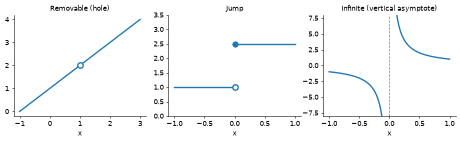

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(9.5, 3))
t1 = np.linspace(-1, 3, 400); t1 = t1[~np.isclose(t1, 1)]
axs[0].plot(t1, t1 + 1, "C0", lw=2); axs[0].plot([1], [2], "o", mfc="white", mec="C0", ms=8, mew=2)
axs[0].set_title("Removable (hole)")
axs[1].plot([-1, 0], [1, 1], "C0", lw=2); axs[1].plot([0, 1], [2.5, 2.5], "C0", lw=2)
axs[1].plot([0], [1], "o", mfc="white", mec="C0", ms=8, mew=2); axs[1].plot([0], [2.5], "o", color="C0", ms=8)
axs[1].set_ylim(0, 3.5); axs[1].set_title("Jump")
tl = np.linspace(-1, -0.02, 300); tr = np.linspace(0.02, 1, 300)
axs[2].plot(tl, 1 / tl, "C0", lw=2); axs[2].plot(tr, 1 / tr, "C0", lw=2)
axs[2].axvline(0, color="gray", ls="--", lw=1); axs[2].set_ylim(-8, 8); axs[2].set_title("Infinite (vertical asymptote)")
for a_ in axs: a_.set_xlabel("x")
plt.tight_layout(); plt.show()

## 7. The intermediate value theorem and bisection

If $f$ is continuous on $[a, b]$ and $f(a)$, $f(b)$ have opposite signs, there is a root in between. **Bisection** looks at the midpoint and keeps the half that still has opposite signs. We record every bracket so we can watch it shrink.

In [16]:
def bisect(func, a, b, tol=1e-6):
    if func(a) * func(b) > 0:
        raise ValueError("func(a) and func(b) must have opposite signs")
    history = []                                   # (a, b, midpoint) at each step
    while b - a > tol:
        m = (a + b) / 2
        history.append((a, b, m))
        if func(a) * func(m) <= 0:                 # the sign change is in [a, m]
            b = m
        else:                                      # the sign change is in [m, b]
            a = m
    return (a + b) / 2, history

cubic = lambda t: t**3 - t - 2
root, hist = bisect(cubic, 1, 2)
print("root ~", round(root, 7), "after", len(hist), "steps; f(root) =", f"{cubic(root):.1e}")
print("brentq (a library root finder):", round(brentq(cubic, 1, 2), 7), "| agree:", np.isclose(root, brentq(cubic, 1, 2), atol=1e-6))
print("\nstep   bracket                      midpoint    f(midpoint)")
for i, (lo, hi, m) in enumerate(hist[:6], 1):
    print(f"{i:>3}   [{lo:.5f}, {hi:.5f}]   {m:.5f}   {cubic(m):+.5f}")

root ~ 1.5213799 after 20 steps; f(root) = 1.4e-06
brentq (a library root finder): 1.5213797 | agree: True

step   bracket                      midpoint    f(midpoint)
  1   [1.00000, 2.00000]   1.50000   -0.12500
  2   [1.50000, 2.00000]   1.75000   +1.60938
  3   [1.50000, 1.75000]   1.62500   +0.66602
  4   [1.50000, 1.62500]   1.56250   +0.25220
  5   [1.50000, 1.56250]   1.53125   +0.05911
  6   [1.50000, 1.53125]   1.51562   -0.03405


The bracket halves each step, so after $n$ steps its width is $(b-a)/2^n$. That predicts how many steps a tolerance needs: about $\log_2\big((b-a)/\text{tol}\big)$.

In [17]:
for tol in [1e-3, 1e-6, 1e-9, 1e-12]:
    _, hst = bisect(cubic, 1, 2, tol)
    print(f"tol = {tol:.0e}: {len(hst):>2} steps   (log2((b-a)/tol) = {np.log2(1 / tol):.1f})")

grid = np.linspace(-1, 1, 2001)
grid = grid[~np.isclose(grid, 0.0)]
print("1/x on [-1, 1]: f(-1) =", 1 / -1, "and f(1) =", 1 / 1, "have opposite signs, yet")
print("the smallest |f| on a fine grid is", np.abs(1 / grid).min(), "so there is no root: f is not continuous at 0.")

tol = 1e-03: 10 steps   (log2((b-a)/tol) = 10.0)
tol = 1e-06: 20 steps   (log2((b-a)/tol) = 19.9)
tol = 1e-09: 30 steps   (log2((b-a)/tol) = 29.9)
tol = 1e-12: 40 steps   (log2((b-a)/tol) = 39.9)
1/x on [-1, 1]: f(-1) = -1.0 and f(1) = 1.0 have opposite signs, yet
the smallest |f| on a fine grid is 1.0 so there is no root: f is not continuous at 0.


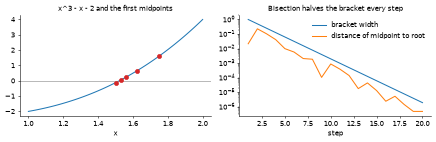

In [18]:
widths = np.array([hi - lo for lo, hi, m in hist])
errors = np.array([abs(m - root) for lo, hi, m in hist])
steps = np.arange(1, len(hist) + 1)
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
tt = np.linspace(1, 2, 100)
axs[0].plot(tt, cubic(tt), "C0"); axs[0].axhline(0, color="gray", lw=0.8)
axs[0].plot([m for _, _, m in hist[:5]], [cubic(m) for _, _, m in hist[:5]], "o", color="C3")
axs[0].set_title("x^3 - x - 2 and the first midpoints"); axs[0].set_xlabel("x")
axs[1].semilogy(steps, widths, "C0", label="bracket width")
axs[1].semilogy(steps, errors + 1e-18, "C1", label="distance of midpoint to root")
axs[1].set_title("Bisection halves the bracket every step"); axs[1].set_xlabel("step"); axs[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 8. Limits at infinity and infinite limits

For a rational function, compare the degrees of top and bottom. Equal degrees give the ratio of leading coefficients. Here $\frac{3x^2 + x}{2x^2 - 5} \to \frac32$ in both directions, so $y = 1.5$ is a horizontal asymptote.

In [19]:
r = lambda t: (3 * t**2 + t) / (2 * t**2 - 5)
for k in [1, 2, 3, 6]:
    big = 10.0**k
    print(f"x = +-1e{k}:  f(x) = {r(big):.6f}   f(-x) = {r(-big):.6f}")

print("\nsmaller degree on top  :", sp.limit(x / (x**2 + 1), x, sp.oo))
print("equal degrees          :", sp.limit((3*x**2 + x) / (2*x**2 - 5), x, sp.oo), sp.limit((3*x**2 + x) / (2*x**2 - 5), x, -sp.oo))
print("bigger degree on top   :", sp.limit(x**3 / (x**2 + 1), x, sp.oo))

x = +-1e1:  f(x) = 1.589744   f(-x) = 1.487179
x = +-1e2:  f(x) = 1.505376   f(-x) = 1.495374
x = +-1e3:  f(x) = 1.500504   f(-x) = 1.499504
x = +-1e6:  f(x) = 1.500001   f(-x) = 1.500000

smaller degree on top  : 0
equal degrees          : 3/2 3/2
bigger degree on top   : oo


**Vertical asymptotes** and infinite limits: look at the sign of the tiny denominator. For $\frac{x+1}{x-2}$ near $x = 2$, the right side goes to $+\infty$ and the left to $-\infty$.

h = 0.1    q(2-h) =      -29.0   q(2+h) =       31.0
h = 0.01   q(2-h) =     -299.0   q(2+h) =      301.0
h = 0.001  q(2-h) =    -2999.0   q(2+h) =     3001.0
sympy: -oo oo


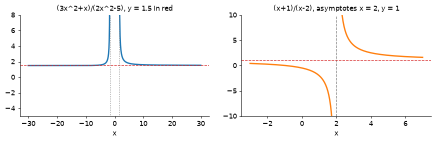

In [20]:
q = lambda t: (t + 1) / (t - 2)
for h in [0.1, 0.01, 0.001]:
    print(f"h = {h:<6} q(2-h) = {q(2 - h):>10.1f}   q(2+h) = {q(2 + h):>10.1f}")
print("sympy:", sp.limit((x + 1) / (x - 2), x, 2, "-"), sp.limit((x + 1) / (x - 2), x, 2, "+"))

fig, axs = plt.subplots(1, 2, figsize=(9, 3))
for lo, hi in [(-30, -1.7), (1.7, 30)]:
    tt = np.linspace(lo, hi, 600)
    axs[0].plot(tt, r(tt), "C0", lw=2)
axs[0].axhline(1.5, color="C3", ls="--", lw=1); axs[0].axvline(np.sqrt(2.5), color="gray", ls=":", lw=1); axs[0].axvline(-np.sqrt(2.5), color="gray", ls=":", lw=1)
axs[0].set_ylim(-5, 8); axs[0].set_title("(3x^2+x)/(2x^2-5), y = 1.5 in red")
for lo, hi in [(-3, 1.97), (2.03, 7)]:
    tt = np.linspace(lo, hi, 600)
    axs[1].plot(tt, q(tt), "C1", lw=2)
axs[1].axvline(2, color="gray", ls="--", lw=1); axs[1].axhline(1, color="C3", ls="--", lw=1)
axs[1].set_ylim(-10, 10); axs[1].set_title("(x+1)/(x-2), asymptotes x = 2, y = 1")
for a_ in axs: a_.set_xlabel("x")
plt.tight_layout(); plt.show()

## 9. Growth rates and the number e

The race has a fixed order: $e^x$ beats every power $x^k$, and every power beats $\ln x$. The ratios below head to $0$.

In [21]:
print(f"{'x':>5} {'x^3':>10} {'e^x':>12} {'ln x':>7} {'x^3/e^x':>12} {'ln x / x':>10}")
for xv in [5, 10, 20, 40, 80]:
    print(f"{xv:>5} {xv**3:>10} {np.exp(xv):>12.3e} {np.log(xv):>7.3f} {xv**3 / np.exp(xv):>12.3e} {np.log(xv) / xv:>10.4f}")
print("sympy:", sp.limit(x**5 / sp.exp(x), x, sp.oo), sp.limit(sp.log(x) / x**sp.Rational(1, 10), x, sp.oo))

    x        x^3          e^x    ln x      x^3/e^x   ln x / x
    5        125    1.484e+02   1.609    8.422e-01     0.3219
   10       1000    2.203e+04   2.303    4.540e-02     0.2303
   20       8000    4.852e+08   2.996    1.649e-05     0.1498
   40      64000    2.354e+17   3.689    2.719e-13     0.0922
   80     512000    5.541e+34   4.382    9.241e-30     0.0548
sympy: 0 0


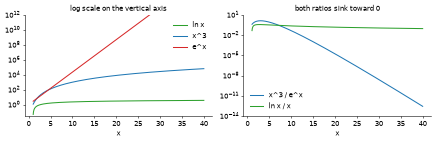

In [22]:
tt = np.linspace(1.05, 40, 600)
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].semilogy(tt, np.log(tt), "C2", label="ln x"); axs[0].semilogy(tt, tt**3, "C0", label="x^3"); axs[0].semilogy(tt, np.exp(tt), "C3", label="e^x")
axs[0].set_ylim(0.03, 1e12); axs[0].legend(frameon=False); axs[0].set_title("log scale on the vertical axis")
axs[1].semilogy(tt, tt**3 / np.exp(tt), "C0", label="x^3 / e^x"); axs[1].semilogy(tt, np.log(tt) / tt, "C2", label="ln x / x")
axs[1].set_ylim(1e-14, 10); axs[1].legend(frameon=False, loc="lower left"); axs[1].set_title("both ratios sink toward 0")
for a_ in axs: a_.set_xlabel("x")
plt.tight_layout(); plt.show()

**$(1 + 1/n)^n$ heads to $e$.** This is numeric evidence, not a proof. The error shrinks roughly like $e/(2n)$. At enormous $n$, however, floating-point rounding takes over: $1 + 10^{-16}$ is stored as exactly $1$, so the formula collapses (a first taste of the stability section).

In [23]:
print(f"{'n':>12} {'(1+1/n)^n':>18} {'error vs e':>12} {'e/(2n)':>10}")
for k in [0, 1, 2, 3, 4, 6, 8, 10, 12, 15, 16]:
    n = 10**k
    val = (1 + 1 / n) ** n
    print(f"{n:>12} {val:>18.12f} {abs(val - np.e):>12.3e} {np.e / (2 * n):>10.1e}")
print("e =", np.e, "| sympy:", sp.limit((1 + 1 / x) ** x, x, sp.oo))

           n          (1+1/n)^n   error vs e     e/(2n)
           1     2.000000000000    7.183e-01    1.4e+00
          10     2.593742460100    1.245e-01    1.4e-01
         100     2.704813829422    1.347e-02    1.4e-02
        1000     2.716923932236    1.358e-03    1.4e-03
       10000     2.718145926825    1.359e-04    1.4e-04
     1000000     2.718280469096    1.359e-06    1.4e-06
   100000000     2.718281798347    3.011e-08    1.4e-08
 10000000000     2.718282053235    2.248e-07    1.4e-10
1000000000000     2.718523496037    2.417e-04    1.4e-12
1000000000000000     3.035035206549    3.168e-01    1.4e-15
10000000000000000     1.000000000000    1.718e+00    1.4e-16
e = 2.718281828459045 | sympy: E


## 10. Saturation: limits at infinity inside a network

Sigmoid tends to $0$ and $1$, and tanh to $-1$ and $1$. The curves flatten there, so their **slope** is nearly $0$ (we derive slopes in the next topic: for sigmoid it is $s(1-s)$, for tanh it is $1 - \tanh^2$). Flat tails are one ingredient of vanishing gradients.

In [24]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
z = np.array([0.0, 2.0, 5.0, 10.0, 20.0])
s = sigmoid(z)
print("z           :", z)
print("sigmoid(z)  :", s)
print("slope s(1-s):", s * (1 - s))
print("tanh(z)     :", np.tanh(z))
print("slope       :", 1 - np.tanh(z) ** 2)

z           : [ 0.  2.  5. 10. 20.]
sigmoid(z)  : [0.5      0.880797 0.993307 0.999955 1.      ]
slope s(1-s): [0.25     0.104994 0.006648 0.000045 0.      ]
tanh(z)     : [0.       0.964028 0.999909 1.       1.      ]
slope       : [1.       0.070651 0.000182 0.       0.      ]


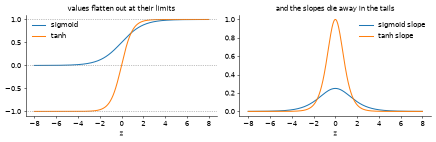

In [25]:
zz = np.linspace(-8, 8, 400)
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
axs[0].plot(zz, sigmoid(zz), label="sigmoid"); axs[0].plot(zz, np.tanh(zz), label="tanh")
axs[0].axhline(1, color="gray", ls=":", lw=1); axs[0].axhline(-1, color="gray", ls=":", lw=1); axs[0].axhline(0, color="gray", ls=":", lw=1)
axs[0].legend(frameon=False); axs[0].set_title("values flatten out at their limits")
axs[1].plot(zz, sigmoid(zz) * (1 - sigmoid(zz)), label="sigmoid slope"); axs[1].plot(zz, 1 - np.tanh(zz) ** 2, label="tanh slope")
axs[1].legend(frameon=False); axs[1].set_title("and the slopes die away in the tails")
for a_ in axs: a_.set_xlabel("z")
plt.tight_layout(); plt.show()

**Softmax with one huge logit** tends to a one-hot vector. (We subtract the maximum first, a trick explained in section 12.) And **continuity**: ReLU is continuous with a corner, the step function jumps.

In [26]:
def softmax(v):
    e = np.exp(v - v.max())
    return e / e.sum()

for big in [1, 5, 20]:
    print(f"logits [{big}, 0, 0]  ->", softmax(np.array([big, 0.0, 0.0])))

relu = lambda v: np.maximum(0.0, v)
step = lambda v: np.where(v >= 0, 1.0, 0.0)
h = 1e-6
print("\nReLU slope at 0 from the left :", (relu(0.0) - relu(-h)) / h)
print("ReLU slope at 0 from the right:", (relu(h) - relu(0.0)) / h, "(a corner: two different slopes, but no gap)")
print("step: value just left/right of 0:", step(-h), step(h), "(a jump) and slope elsewhere:", (step(1.0 + h) - step(1.0)) / h)

logits [1, 0, 0]  -> [0.576117 0.211942 0.211942]
logits [5, 0, 0]  -> [0.986703 0.006648 0.006648]
logits [20, 0, 0]  -> [1. 0. 0.]

ReLU slope at 0 from the left : 0.0
ReLU slope at 0 from the right: 1.0 (a corner: two different slopes, but no gap)
step: value just left/right of 0: 0.0 1.0 (a jump) and slope elsewhere: 0.0


## 11. Finite differences: the limit as a tool, and its sweet spot

The slope of $f$ at $x_0$ is the limit of $\frac{f(x_0 + h) - f(x_0)}{h}$ as $h \to 0$. On a computer we use a small but nonzero $h$. The **centered** version $\frac{f(x_0+h) - f(x_0-h)}{2h}$ is more accurate. Watch the error as $h$ shrinks: it falls (the limit at work), hits a floor, and then **rises** again, because the two function values agree in almost all digits and their difference is mostly rounding noise.

forward : best h = 1.4e-08, smallest error = 1.7e-09
centered: best h = 2.7e-06, smallest error = 2.9e-12
rule of thumb: forward ~ sqrt(eps) = 1.5e-08, centered ~ eps^(1/3) = 6.1e-06


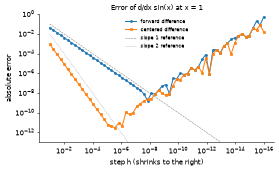

In [27]:
hs = np.logspace(-1, -16, 60)
def fd_errors(func, dfunc, x0):
    fwd = (func(x0 + hs) - func(x0)) / hs
    ctr = (func(x0 + hs) - func(x0 - hs)) / (2 * hs)
    return np.abs(fwd - dfunc(x0)), np.abs(ctr - dfunc(x0))

e_fwd, e_ctr = fd_errors(np.sin, np.cos, 1.0)
print("forward : best h = %.1e, smallest error = %.1e" % (hs[e_fwd.argmin()], e_fwd.min()))
print("centered: best h = %.1e, smallest error = %.1e" % (hs[e_ctr.argmin()], e_ctr.min()))
print("rule of thumb: forward ~ sqrt(eps) = %.1e, centered ~ eps^(1/3) = %.1e" % (np.sqrt(np.finfo(float).eps), np.finfo(float).eps ** (1 / 3)))

fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.loglog(hs, e_fwd, "o-", ms=3, label="forward difference")
ax.loglog(hs, e_ctr, "s-", ms=3, label="centered difference")
ax.loglog(hs, hs, "--", color="gray", lw=0.8, label="slope 1 reference")
ax.loglog(hs, hs**2, ":", color="gray", lw=0.8, label="slope 2 reference")
ax.set_ylim(1e-13, 1); ax.invert_xaxis(); ax.set_xlabel("step h (shrinks to the right)"); ax.set_ylabel("absolute error")
ax.set_title("Error of d/dx sin(x) at x = 1"); ax.legend(frameon=False, fontsize=8)
plt.show()

This is exactly how a **gradient check** works in practice: compare the gradient you derived by hand with a centered finite difference, coordinate by coordinate. We use a tiny squared-error loss with invented numbers and check the relative error.

In [28]:
xin, target = np.array([0.5, -1.2, 2.0]), 1.5
loss = lambda w: (w @ xin - target) ** 2
grad = lambda w: 2 * (w @ xin - target) * xin       # derived by hand

w0 = np.array([0.3, 0.8, -0.4])
numeric = np.zeros(3)
for i in range(3):
    step_ = np.zeros(3); step_[i] = 1e-5
    numeric[i] = (loss(w0 + step_) - loss(w0 - step_)) / 2e-5
print("analytic:", grad(w0))
print("numeric :", numeric)
rel = np.linalg.norm(numeric - grad(w0)) / np.linalg.norm(numeric + grad(w0))
print("relative error: %.1e" % rel, "| gradient looks right:", bool(rel < 1e-7))

analytic: [ -3.11    7.464 -12.44 ]
numeric : [ -3.11    7.464 -12.44 ]
relative error: 5.3e-12 | gradient looks right: True


## 12. Numerical stability near a limit

Rounding errors bite where a formula is a limit in disguise: tiny inputs, $0/0$, and huge exponents. Four standard repairs: `log1p`, `expm1`, a rewritten fraction, and the log-sum-exp trick.

In [29]:
np.seterr(all="ignore")                             # silence warnings we provoke on purpose
for t in [1e-5, 1e-10, 1e-17]:
    print(f"t = {t:.0e}  log(1+t) = {np.log(1 + t):.10e}  log1p(t) = {np.log1p(t):.10e}")
    print(f"{'':10}  exp(t)-1 = {np.exp(t) - 1:.10e}  expm1(t) = {np.expm1(t):.10e}")

print("\n(1 - cos t)/t^2 has limit 0.5 as t -> 0:")
for t in [1e-2, 1e-4, 1e-6, 1e-8]:
    print(f"t = {t:.0e}  naive = {(1 - np.cos(t)) / t**2:.6f}   rewritten 2 sin^2(t/2)/t^2 = {2 * np.sin(t / 2)**2 / t**2:.6f}")

zero = np.float64(0.0)
print("\n0/0 gives:", zero / zero, "| 0 * log(0) gives:", zero * np.log(zero), "| xlogy(0, 0) gives:", xlogy(0.0, 0.0))

t = 1e-05  log(1+t) = 9.9999500004e-06  log1p(t) = 9.9999500003e-06
            exp(t)-1 = 1.0000050000e-05  expm1(t) = 1.0000050000e-05
t = 1e-10  log(1+t) = 1.0000000827e-10  log1p(t) = 9.9999999995e-11
            exp(t)-1 = 1.0000000827e-10  expm1(t) = 1.0000000001e-10
t = 1e-17  log(1+t) = 0.0000000000e+00  log1p(t) = 1.0000000000e-17
            exp(t)-1 = 0.0000000000e+00  expm1(t) = 1.0000000000e-17

(1 - cos t)/t^2 has limit 0.5 as t -> 0:
t = 1e-02  naive = 0.499996   rewritten 2 sin^2(t/2)/t^2 = 0.499996
t = 1e-04  naive = 0.500000   rewritten 2 sin^2(t/2)/t^2 = 0.500000
t = 1e-06  naive = 0.500044   rewritten 2 sin^2(t/2)/t^2 = 0.500000
t = 1e-08  naive = 0.000000   rewritten 2 sin^2(t/2)/t^2 = 0.500000

0/0 gives: nan | 0 * log(0) gives: nan | xlogy(0, 0) gives: 0.0


In [30]:
logits = np.array([1000.0, 1001.0, 1002.0])
naive = np.log(np.sum(np.exp(logits)))               # exp(1000) overflows to inf
m = logits.max()
stable = m + np.log(np.sum(np.exp(logits - m)))      # subtract the max first
print("naive log-sum-exp :", naive)
print("stable            :", stable, "| scipy:", logsumexp(logits), "| agree:", np.isclose(stable, logsumexp(logits)))
print("naive softmax     :", np.exp(logits) / np.exp(logits).sum())
print("stable softmax    :", np.exp(logits - stable))

naive log-sum-exp : inf
stable            : 1002.4076059644444 | scipy: 1002.4076059644444 | agree: True
naive softmax     : [nan nan nan]
stable softmax    : [0.090031 0.244728 0.665241]


## Summary

- A limit is where the outputs are **heading**; tables of values, one-sided limits, and graphs reveal it, and SymPy's `limit` computes it exactly.
- Continuity is "limit equals value". Discontinuities are removable (a hole), jump, or infinite. The intermediate value theorem is what makes bisection work, and it needs continuity.
- Limits at infinity explain asymptotes and saturation. The growth order is $\ln x \ll x^k \ll e^x$, and $(1+1/n)^n \to e$.
- Finite-difference derivatives approximate a limit, with a best step size well above the smallest possible one. Stable code (`log1p`, `expm1`, log-sum-exp, `xlogy`) avoids the traps near limits.

Next, [Derivatives and Taylor Series](../derivatives-and-taylor-series/README.md) turns the finite-difference limit from section 11 into the main tool of calculus.